In [37]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'GPU: Tesla T4'

In [38]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [39]:
# %load_ext cuml.accel
# %load_ext cudf.pandas

In [40]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

In [41]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random
from scipy.stats import norm

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep

## -- Machine Learning --
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import TargetEncoder as skTE
from sklearn.model_selection import KFold, train_test_split

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

# SEED = 42
# random.seed(SEED)
# np.random.seed(SEED)
# os.environ["PYTHONHASHSEED"] = str(SEED)

warnings

<module 'warnings' from '/usr/lib/python3.13/warnings.py'>

In [42]:
try:
    from bartz.BART import gbart, mc_gbart
except:
    !uv pip install -q bartz
    from bartz.BART import gbart, mc_gbart

!pip show bartz

Name: bartz
Version: 0.13.0
Summary: Super-fast BART (Bayesian Additive Regression Trees) in Python
Home-page: https://github.com/bartz-org/bartz
Author: 
Author-email: Giacomo Petrillo <info@giacomopetrillo.com>
License-Expression: MIT
Location: /usr/local/lib/python3.13/dist-packages
Requires: equinox, jax, jaxtyping, numpy, scipy, tqdm, typing-extensions
Required-by: 


In [43]:
## -- Tell JAX to use all and only 95% of the GPU memory
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = '.95'

print("📥 Memory limited to 95% usage")

📥 Memory limited to 95% usage


In [44]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 12,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})

sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [45]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "colab" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e10/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")

    ORIG_PATH = "/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/"
    orig = pd.read_csv(ORIG_PATH+"data.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")

    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e10 | Airline Satisfaction/_airline_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"data.csv")

## =================================================================================

TARGET, ID = 'satisfaction', 'id'

train[TARGET] = train[TARGET].map({True: 1, False: 0})
orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET, ID]]
num_cols  = [c for c in train.columns if c not in cat_cols+[TARGET, ID]]
base_cols = [c for c in train.columns if c not in [TARGET, ID]]

service_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
    'Inflight entertainment', 'On-board service', 'Leg room service',
    'Baggage handling', 'Checkin service', 'Cleanliness'
]

train = train[base_cols+[TARGET]]
orig  = orig[base_cols+[TARGET]]
test  = test[base_cols]

print(f"Frame type: {type(train)}\n")

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total base features: {len(base_cols)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Frame type: <class 'pandas.core.frame.DataFrame'>

Train shape: (699635, 22)
Test shape: (299844, 21)
Orig shape: (129880, 22)
Total Numerical: 17
Total Categorical: 4
Total base features: 21


In [46]:
train['Arrival Delay in Minutes'] = train['Arrival Delay in Minutes'].fillna(0.0)
test['Arrival Delay in Minutes']  = test['Arrival Delay in Minutes'].fillna(0.0)
orig['Arrival Delay in Minutes']  = orig['Arrival Delay in Minutes'].fillna(0.0)

In [47]:
# # import pandas as pd
# from pandas.util import hash_pandas_object

# # Generate hashes
# hash1 = hash_pandas_object(train[base_cols], index=False)
# hash2 = hash_pandas_object(test[base_cols], index=False)

# # Find rows where they don't match
# mismatches = hash1 != hash2
# # print("Rows that changed:", mismatches)

In [48]:
# train.head()

In [49]:
# train.describe().T

In [50]:
train_len = len(train)
test_len  = len(test)

n_unique = train.nunique().sort_values()
n_unique

,0
satisfaction,2
Type of Travel,2
Customer Type,2
Gender,2
Class,3
Baggage handling,5
Gate location,6
Departure/Arrival time convenient,6
Leg room service,6
Checkin service,6


In [51]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}

        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)

        return X

In [52]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df.astype('float32'), on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


## FEATURE ENGINEERING

In [53]:
## -- DIGITS EXTRACTION --

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]

combined = pd.concat([train, test, orig])

digit_cols = []
cols_select = ["Flight Distance"] #, "Age", "Arrival Delay in Minutes", "Departure Delay in Minutes"]

for col in cols_select:
    scaled = (combined[col].fillna(0) * (10**4)).astype('int64')
    for k in [3]:
        dig_col = f"{col}_dig_{k}"
        combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int32').astype('category')
        # combined[dig_col] = (combined[col].fillna(0) // (10**k) % 10).astype('int32').astype('category')
        digit_cols.append(dig_col)

train = combined.iloc[:train_len]
test = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig = combined.iloc[-len(orig):]

# Check nunique, and find which ones are < 2
unique_counts = train[digit_cols].nunique()
drop_cols = unique_counts[unique_counts < 2].index.tolist()

# update digit cols for keep
digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# drop constant features
train = train.drop(columns=drop_cols)
test  = test.drop(columns=drop_cols)
orig  = orig.drop(columns=drop_cols)

del combined
print(f"Total digit features: {len(digit_cols)}\n")

train[digit_cols].nunique()

Total digit features: 1



,0
Flight Distance_dig_3,5


In [54]:
# ## -- Cyclic encoding --

# for df in [train, test]:
#     for p in [8, 12, 24]:
#         df[f"sleep_hours_sin_{p}"] = np.sin(2 * np.pi * df["sleep_hours"] / p).astype("float32")
#         df[f"sleep_hours_cos_{p}"] = np.cos(2 * np.pi * df["sleep_hours"] / p).astype("float32")

In [55]:
## -- NUMERIC TO CATEGORY for TargetEncoding -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Features before operation:", len(FEATURES))

combined = pd.concat([train, test, orig])
## ------------------------------------------------------------

# -- Duplicate Nums as Cats --
nums_to_cats = []
select_nc = ["Flight Distance", "Age"] #, "Age", "Arrival Delay in Minutes", "Departure Delay in Minutes"]
for c in tqdm(select_nc, desc="nums_to_cats"):
    new_cat = f"{c}_cat_"
    combined[new_cat] = (pd.factorize(combined[c])[0]).astype('int32')
    # combined[n] = combined[n].astype('category')
    nums_to_cats.append(new_cat)
FEATURES = list(set(FEATURES + nums_to_cats))

## ------------------------------------------------------------
train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print("Features after operation:", len(FEATURES))

Features before operation: 22


nums_to_cats:   0%|          | 0/2 [00:00<?, ?it/s]

Features after operation: 24


In [56]:
# ## -- Frequency encoding -- ⚠️
# freq_cols = []

# combined = pd.concat([train, test], ignore_index=True)
# select_freq = ["Flight Distance"] #, "Age", "Arrival Delay in Minutes", "Departure Delay in Minutes"]

# print("\nCreating frequencies (Safe Global Mapping)...")
# for col in select_freq:
#     n = f"_freq_{col}"
#     print(f"⧗ {n}", end="")

#     # Calculate frequencies using ONLY train
#     freq_map = train[col].value_counts(dropna=False, normalize=False).to_dict()

#     # Map the training-derived frequencies across all datasets safely
#     train[n] = train[col].map(freq_map).fillna(0).astype("float32")
#     test[n] = test[col].map(freq_map).fillna(0).astype("float32")
#     orig[n] = orig[col].map(freq_map).fillna(0).astype("float32")

#     freq_cols.append(n)
#     print()

# # num_cols = list(set(num_cols + freq_cols))
# FEATURES = list(set(FEATURES + freq_cols))

# print(f"\n *** Total frequency features: {len(freq_cols)}")

In [57]:
## -- Factorize cat_cols -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Total features before operation:", len(FEATURES))

combined = pd.concat([train, test, orig])
## ------------------------------------------------------------------------
for c in tqdm(cat_cols, desc="factorize_cats"):
    combined[c] = (pd.factorize(combined[c])[0]).astype('int32')

## ------------------------------------------------------------------------
# groupers = []
# for col in service_cols:
#     n_col = f"{col}_Distance_GROUPBY".replace(" ", "")
#     combined[n_col] = combined.groupby(['Flight Distance'])[col].transform('mean')
#     groupers.append(n_col)
# FEATURES = list(set(FEATURES + groupers))
## ------------------------------------------------------------------------

for c in tqdm(cat_cols, desc="categorize_cats"):
    combined[c] = combined[c].astype("category")

train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print("Total features after operation:", len(FEATURES))

Total features before operation: 24


factorize_cats:   0%|          | 0/4 [00:00<?, ?it/s]

categorize_cats:   0%|          | 0/4 [00:00<?, ?it/s]

Total features after operation: 24


In [58]:
# ## FLOOR/BIN FEATURES -- ⚠️
# floor_cols = []

# combined = pd.concat([train, test, orig])

# # for f in tqdm([1000], desc='Floor features (bins)'):
# #     # print(f, end='-> ')
# #     for c in ['Flight Distance']:
# #         f_name = f"{c}_flr{f}"
# #         print(f" ⧗ {f_name}", end='... ')
# #         combined[f_name] = (combined[c].fillna(0) // f).astype('int32')
# #         # combined[f_name] = (combined[c].fillna(0) // f).astype('int32').astype('category')
# #         floor_cols.append(f_name)
# #         print()

# # for f in tqdm([10], desc='Floor features (bins)'):
# #     # print(f, end='-> ')
# #     for c in ['Departure Delay in Minutes', 'Arrival Delay in Minutes']:
# #         f_name = f"{c}_//_{f}"
# #         print(f" ⧗ {f_name}", end='... ')
# #         combined[f_name] = (combined[c] // f).astype('int32')
# #         floor_cols.append(f_name)
# #         print()

# for f in tqdm([5], desc='Floor features (bins)'):
#     # print(f, end='-> ')
#     for c in ['Age']:
#         age_n = f"{c}_flr{f}"
#         print(f" ⧗ {age_n}", end='... ')
#         combined[age_n] = (combined[c] // f).astype('int32')
#         floor_cols.append(age_n)
#         print()

# # combined[f"age{f}_X_dist1000"] = combined[age_n] * combined[f_name]

# # FEATURES = list(set(FEATURES + floor_cols))

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined
# print(f"\n*** Total floor features: {len(floor_cols)}")

# print(train[floor_cols].nunique(dropna=False))

In [59]:
## -- INTERACTIONS -- ⚠️

INTER = []

combo_select = [c for c in base_cols if train[c].nunique() < 10] + ['Flight Distance_//_250', 'Age_//_10']
comb = [c for c in num_cols if (train[c].nunique() < 10) and (c in base_cols)]

combined = pd.concat([train, test, orig], ignore_index=True)
# ------------------------------------------------------------------------
# combo_2_1 = list(itertools.combinations(cat_cols, 2))
# for c1, c2 in tqdm(combo_2_1, desc='Pairwise Sync Encoding'):
#     n_col = f"Bi_{c1}_X_{c2}".strip()
#     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
#     combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
#     # combined[n_col] = combined[n_col].astype('category')
#     INTER.append(n_col)

combo_3_1 = list(itertools.combinations(cat_cols, 3)) # + [age_n]
for c1, c2, c3 in tqdm(combo_3_1, desc='Triplewise Sync Encoding'):
    n_col = f"Tri_{c1}_X_{c2}_X_{c3}".strip()
    combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str) + '_' + combined[c3].astype(str)
    combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
    # combined[n_col] = combined[n_col].astype('category')
    INTER.append(n_col)

# combo_1_to_many = list(itertools.product(cat_cols, [age_n]))
# for c1, c2 in tqdm(combo_1_to_many, desc='One-2-Many Sync Encoding'):
#     n_col = f"Bi2_{c1}_X_{c2}".strip()
#     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
#     combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
#     # combined[n_col] = combined[n_col].astype('category')
#     INTER.append(n_col)
# ------------------------------------------------------------------------

for n_col in INTER:
    train[n_col] = combined[n_col].iloc[:train_len].values
    test[n_col]  = combined[n_col].iloc[train_len:train_len + test_len].values
    orig[n_col]  = combined[n_col].iloc[train_len + test_len:].values

print(f"Total Interaction Features: {INTER}")

del combined
# train[INTER].head()

Triplewise Sync Encoding:   0%|          | 0/4 [00:00<?, ?it/s]

Total Interaction Features: ['Tri_Gender_X_Customer Type_X_Type of Travel', 'Tri_Gender_X_Customer Type_X_Class', 'Tri_Gender_X_Type of Travel_X_Class', 'Tri_Customer Type_X_Type of Travel_X_Class']


In [60]:
# # ==========================================
# # 2. HIGH-IMPACT DOMAIN INTERACTIONS (AUC BOOST) ⚠️
# # ==========================================

# combined = pd.concat([train, test, orig])

# service_cols = [
#     'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
#     'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
#     'Inflight entertainment', 'On-board service', 'Leg room service',
#     'Baggage handling', 'Checkin service', 'Cleanliness'
# ]

# # # A. Total Delay & Delay Discrepancy
# # # Tree models easily split on raw values, but explicit sums and differences reduce required tree depth
# # combined['Total_Delay'] = combined['Departure Delay in Minutes'].fillna(0) + combined['Arrival Delay in Minutes'].fillna(0)
# # combined['Delay_Recovered'] = combined['Departure Delay in Minutes'].fillna(0) - combined['Arrival Delay in Minutes'].fillna(0)
# # combined['Is_Delayed'] = (combined['Total_Delay'] > 0).astype('int8').astype('category')

# # # B. Aggregated Service Experience Scores (Crucial for Passenger Satisfaction datasets)
# # # Capturing the holistic experience mathematically
# # combined['Total_Service_Score'] = combined[service_cols].sum(axis=1)
# # combined['Mean_Service_Score']  = combined[service_cols].mean(axis=1)
# # combined['Variance_Service_Score'] = combined[service_cols].var(axis=1).astype('float32')

# # Segmenting critical service groups
# booking_flow = ['Inflight wifi service', 'Ease of Online booking', 'Online boarding']
# comfort_flow = ['Seat comfort', 'Food and drink', 'Leg room service', 'Cleanliness']
# combined['Digital_Experience_Score'] = combined[booking_flow].mean(axis=1)
# combined['Physical_Comfort_Score'] = combined[comfort_flow].mean(axis=1)

# # # Count of zero-scores (often represents "Not Applicable" or an extreme pain point)
# # combined['Count_Zero_Services'] = (combined[service_cols] == 0).sum(axis=1).astype('int8')

# # # C. Distance vs. Age Groupings
# # combined['Distance_per_Year_of_Age'] = combined['Flight Distance'] / (combined['Age'] + 1)

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined
# print("Arithmetric features ready")

In [61]:
train.nunique()[-20:]

,0
Inflight entertainment,6
On-board service,6
Leg room service,6
Baggage handling,5
Checkin service,6
Cleanliness,6
Departure Delay in Minutes,167
Arrival Delay in Minutes,168
Gender,2
Customer Type,2


# ML TRAINING

In [62]:
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    train,
    train_size=50_000,
    stratify=train[TARGET],
    random_state=42
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
print(train_X.shape, type(train_X))

_ = [c for c in train_X.columns if c not in [ID, TARGET]]
FEATURES = list(set(_))

print(f"Train shape {train_X.shape}")
# train_X.head()

(699635, 29) <class 'pandas.core.frame.DataFrame'>
Train shape (699635, 29)


In [63]:
## -- Handle optional original table aggregations
USE_ORIGINAL = True

import_cols = ['Flight Distance'] # + cat_cols + service_cols

if USE_ORIGINAL:
    aggs_ = ["mean"]  # "mean", "count", "std", "skew", "nunique",
    feats = FEATURES.copy()
    x_train, orig_cols = original_TE(
        orig, train_X, target=TARGET, features = import_cols,
        aggs=aggs_, fill_nan=True
    )
    x_test, _ = original_TE(
        orig, test, target=TARGET, features = import_cols,
        aggs=aggs_, fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype("int32")
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype("int32")

print(X.shape, type(X))
X.head()

original_augmenting:   0%|          | 0/1 [00:00<?, ?it/s]

original_augmenting:   0%|          | 0/1 [00:00<?, ?it/s]

(699635, 29) <class 'pandas.core.frame.DataFrame'>


,Leg room service,Age,Customer Type,Gender,Tri_Gender_X_Type of Travel_X_Class,Online boarding,Type of Travel,Class,Inflight wifi service,Flight Distance_cat_,Arrival Delay in Minutes,Gate location,Age_cat_,Departure/Arrival time convenient,Baggage handling,Flight Distance_dig_3,On-board service,Flight Distance,Seat comfort,Checkin service,Departure Delay in Minutes,Cleanliness,Tri_Customer Type_X_Type of Travel_X_Class,Ease of Online booking,Tri_Gender_X_Customer Type_X_Type of Travel,Inflight entertainment,Tri_Gender_X_Customer Type_X_Class,Food and drink,oTE_Flight Distance_mean
0,4,36,0,0,0,4,0,0,4,0,0.0,3,0,4,4,0,3,694,1,3,0,1,0,4,0,1,0,1,0.351852
1,5,56,0,1,1,4,1,1,5,1,0.0,5,1,5,5,0,5,651,4,4,0,3,1,5,1,5,1,5,0.331915
2,3,31,0,0,0,3,0,0,3,2,0.0,5,2,4,4,1,4,1371,3,5,0,3,0,2,0,3,0,3,0.428571
3,5,10,0,1,2,3,0,0,3,3,0.0,3,3,5,3,1,4,1616,3,4,0,3,0,3,2,3,2,3,0.443038
4,4,23,1,0,3,3,1,0,3,4,0.0,4,4,4,5,0,5,481,5,3,5,5,2,3,3,5,3,5,0.343750


In [64]:
# pd.concat([X[groupers+INTER], y], axis=1).corr()

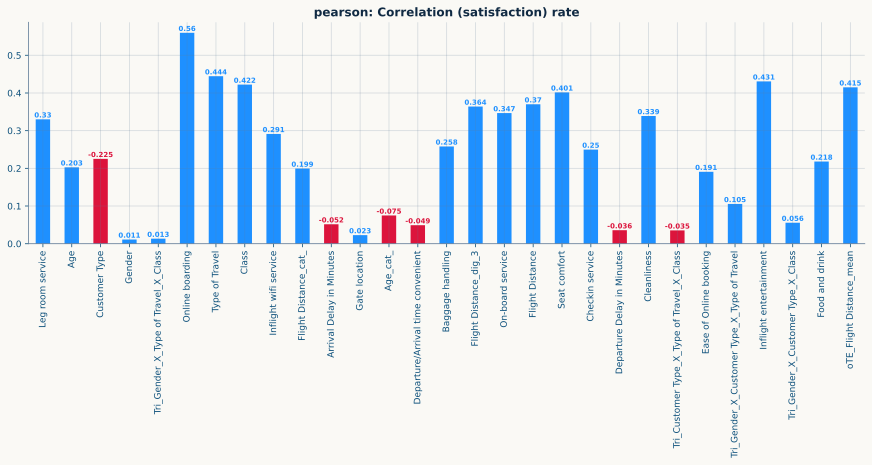

In [65]:
corr_type = ['pearson', 'spearman'][0]

plt.figure(figsize=(15, 4))
corr_df = X.corrwith(train_X[TARGET], method=corr_type)
corr_df.abs().plot(kind='bar', color=[CRIM if c < 0 else BLUE for c in corr_df.values])
for i, v in enumerate(corr_df.values):
    plt.text(
        i, np.abs(v) + 0.001, np.round(v, 3),
        size=7, weight='semibold', color=CRIM if v < 0 else BLUE,
        va='bottom', ha='center',
    )

plt.title(f"{corr_type}: Correlation ({TARGET}) rate")
plt.show()

In [66]:
## -- Reduce data memory --

def reduce_memory(df):
    old_size = df.memory_usage(deep=True).sum() / (1024*1024)
    for c in tqdm(df.columns, desc='Reducing memory...'):
        if df[c].dtype == np.int64:
            ## -- Downcast Integer type ---
            if df[c].min() > np.iinfo(np.int32).min and df[c].max() < np.iinfo(np.int32).max:
                df[c] = df[c].astype(np.int32)
                # if df[c].min() > np.iinfo(np.int16).min and df[c].max() < np.iinfo(np.int16).max:
                #     df[c] = df[c].astype(np.int16)
                #     if df[c].min() > np.iinfo(np.int8).min and df[c].max() < np.iinfo(np.int8).max:
                #         df[c] = df[c].astype(np.int8)
        elif df[c].dtype == np.float64:
            ## -- Downcast Float type -----
            if df[c].min() > np.finfo(np.float32).min and df[c].max() < np.finfo(np.float32).max:
                df[c] = df[c].astype(np.float32)
                # if df[c].min() > np.finfo(np.float16).min and df[c].max() < np.finfo(np.float16).max:
                #     df[c] = df[c].astype(np.float16)

    new_size = df.memory_usage(deep=True).sum() / (1024*1024)
    print(f"Size before process: {old_size:.1f} MB\nSize after process : {new_size:.1f}MB\n")

    return df

X = reduce_memory(X)
X_test = reduce_memory(X_test)
# orig = reduce_memory(orig)

print(f"Data memory reduced!")
gc.collect()

Reducing memory...:   0%|          | 0/29 [00:00<?, ?it/s]

Size before process: 115.4 MB
Size after process : 67.4MB



Reducing memory...:   0%|          | 0/29 [00:00<?, ?it/s]

Size before process: 49.5 MB
Size after process : 28.9MB

Data memory reduced!


8586

In [81]:
class CFG:
    FOLDS = 5
    SEED = 42
    TE = True if 'nums_to_cats' in globals() else False
    ES = 50 # 50, 250
    VERB = 100 # 100, 300

predict_test = True

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

model_name = 'BARTZp_se'
print(f"\n🚀 Training {model_name} with {FOLDS } Folds")

oof_preds  = np.zeros(len(train_X))
test_preds = np.zeros(len(X_test))

fold_scores = []
best_iterations = []
feat_importances = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr = X.iloc[tr_idx].copy()
    X_val = X.iloc[val_idx].copy()
    y_tr = y.iloc[tr_idx]
    y_val = y.iloc[val_idx]
    X_tst = X_test.copy()

    # Target encoding
    if CFG.TE:
        te_cols = nums_to_cats + INTER # + floor_cols
        # te_cols = nums_to_cats + INTER # + floor_cols + digit_cols + bin_cols
        smooth = 'auto'
        print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
        TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        tr_enc = TE.fit_transform(X_tr[te_cols], y_tr)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE{smooth}_{col}" for col in te_cols]
        X_tr[te_names]  = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = te_cols

        X_tr  = X_tr.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)
    # ------------------------------------------------------------------------------
    if fold == 1: print(f"train={X_tr.shape}, valid={X_val.shape}\n")
    print("#"*16)
    print(f"### Fold {fold}/{FOLDS} ...")
    print("#"*16)

    params = {
        "type": 'pbart',
        'ntree':  100, # d=50
        'mc_cores': 4, # d=2
        'keepevery': 50, # d=10
        # 'k': 4.0, # d=2.0
        # #'ndpost': 500, # d=1000
        # # 'nskip':  150, # d=100
        # # 'numcut': 255, # d=100
        # # 'usequants': True,
        # #'sparse': True,
        # #'augment':True,
        "seed": 42,
    }

    seeder = 42 #+ (fold-1)
    params['seed'] = seeder

    model = mc_gbart(
        X_tr.to_numpy(),
        y_tr.astype(bool).to_numpy() if params['type']=="pbart" else y_tr.astype('float32').to_numpy(),
        # x_test=X_tst.to_numpy(),
        **params,
    )

    val_preds = norm.cdf(model.predict(X_val.to_numpy()).mean(axis=0).ravel())
    oof_preds[val_idx] = val_preds

    if predict_test:
        t_ = time()
        print("⧗ test predictions... ", end="")
        fold_test_preds = norm.cdf(model.predict(X_tst.to_numpy()).mean(axis=0).ravel())
        test_preds += fold_test_preds / FOLDS
        print(f"{(time()-t_)/60:.3f} min")

    # ------------------------------------------------------------------------------------

    fold_score = roc_auc_score(y_val, val_preds)
    fold_scores.append(fold_score)

    best_iter = model.ndpost
    best_iterations.append(best_iter)

    print(f"{Fore.YELLOW}{Style.BRIGHT}Fold {fold} | AUC: {fold_score:.6f}{Style.RESET_ALL}", end=" | ")
    print(f"seed={seeder}, tree={best_iter}\n")
    torch.cuda.empty_cache()

model_name = model_name + f"({X_tr.shape[1]})"
features_used = X_tr.columns

## -- CV results --
fold_results = {}

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_tr.shape}")
print(f"{'='*50}")
for i, (s, t) in enumerate(zip(fold_scores, best_iterations), 1):
    print(f" • Fold {i} AUC: {s:.6f} @ tree {t}")
    fold_results[f'fold_{i}'] = s

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 6)
avg_auc = np.round(np.mean(fold_scores), 6)
std_auc = np.round(np.std(fold_scores), 6)

print("-"*50)
print(f"OOF score: {Fore.BLUE}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.BLUE}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)

t1 = time()
tt = (t1-t0) / 60
print(f"{tt:.2f} mins\n")

del X_tr, X_val, y_tr, y_val, model


🚀 Training BARTZp_se with 5 Folds
⚡️ scikit_TE (smooth=auto) | features (6)
train=(559708, 29), valid=(139927, 29)

################
### Fold 1/5 ...
################


train   0%|          | 0/12600 [00:00<?, ?it/s]

⧗ test predictions... 0.247 min
Fold 1 | AUC: 0.959973 | seed=42, tree=1000

⚡️ scikit_TE (smooth=auto) | features (6)
################
### Fold 2/5 ...
################


train   0%|          | 0/12600 [00:00<?, ?it/s]

⧗ test predictions... 0.235 min
Fold 2 | AUC: 0.958787 | seed=42, tree=1000

⚡️ scikit_TE (smooth=auto) | features (6)
################
### Fold 3/5 ...
################


...

⧗ test predictions... 0.235 min
Fold 3 | AUC: 0.960618 | seed=42, tree=1000

⚡️ scikit_TE (smooth=auto) | features (6)
################
### Fold 4/5 ...
################


train   0%|          | 0/12600 [00:00<?, ?it/s]

⧗ test predictions... 0.234 min
Fold 4 | AUC: 0.960036 | seed=42, tree=1000

⚡️ scikit_TE (smooth=auto) | features (6)
################
### Fold 5/5 ...
################


train   0%|          | 0/12600 [00:00<?, ?it/s]

⧗ test predictions... 0.232 min
Fold 5 | AUC: 0.959894 | seed=42, tree=1000


5-FOLD CV: BARTZp_se(29) | (559708, 29)
 • Fold 1 AUC: 0.959973 @ tree 1000
 • Fold 2 AUC: 0.958787 @ tree 1000
 • Fold 3 AUC: 0.960618 @ tree 1000
 • Fold 4 AUC: 0.960036 @ tree 1000
 • Fold 5 AUC: 0.959894 @ tree 1000
--------------------------------------------------
OOF score: 0.959856
AVG score: 0.959862 ± 0.000595
--------------------------------------------------
31.27 mins



In [82]:
# 'ntree':  100,
# 'mc_cores': 4,
# 'keepevery': 50,
# ==================================================
# 5-FOLD CV: BARTZp_se(29) | (559708, 29)
# ==================================================
#  • Fold 1 AUC: 0.959973 @ tree 1000
#  • Fold 2 AUC: 0.958787 @ tree 1000
#  • Fold 3 AUC: 0.960618 @ tree 1000
#  • Fold 4 AUC: 0.960036 @ tree 1000
#  • Fold 5 AUC: 0.959894 @ tree 1000
# --------------------------------------------------
# OOF score: 0.959856
# AVG score: 0.959862 ± 0.000595
# --------------------------------------------------
# 31.27 mins

# ==================================================
# 5-FOLD CV: BARTZp_se(29) | (559708, 29)
# ==================================================
#  • Fold 1 AUC: 0.959377 @ tree 1000
#  • Fold 2 AUC: 0.957740 @ tree 1000
#  • Fold 3 AUC: 0.959791 @ tree 1000
#  • Fold 4 AUC: 0.959248 @ tree 1000
#  • Fold 5 AUC: 0.959143 @ tree 1000
# --------------------------------------------------
# OOF score: 0.959052
# AVG score: 0.95906 ± 0.000696
# --------------------------------------------------
# 4.15 mins

In [83]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

fold_df = pd.DataFrame.from_dict(fold_results, orient='index', columns=['score'])
print(fold_df.to_string())

print("-"*25)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print("-"*25)

print(f"{tt:.2f} mins")

           score
fold_1  0.959973
fold_2  0.958787
fold_3  0.960618
fold_4  0.960036
fold_5  0.959894
-------------------------
BARTZp_se(29)_959862
-------------------------
31.27 mins


In [84]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit

,id,satisfaction
0,699635,0.233267
1,699636,0.863902
2,699637,0.911330
3,699638,0.065150
4,699639,0.054977
...,...,...
299839,999474,0.042112
299840,999475,0.069577
299841,999476,0.211186
299842,999477,0.022818


In [85]:
# !rm -r /kaggle/working

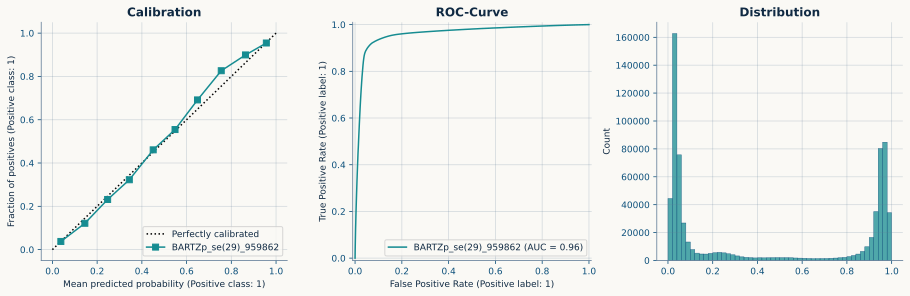

In [86]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12.5, 4))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

# for ax in axs:
#     ax.legend(loc='lower right')

plt.tight_layout(pad=0.2)
plt.show()

Total used features: 29



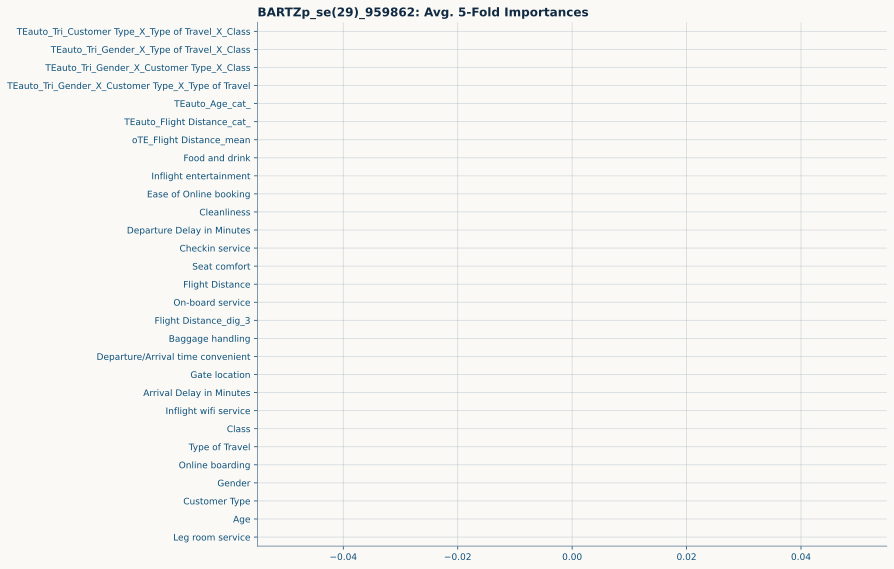

In [87]:
## -- Feature Importances --
top_n_features = 30

imp_df = pd.Series(np.mean(feat_importances, axis=0), index=features_used).sort_values()
print(f"Total used features: {len(imp_df)}\n")

ax = imp_df[-top_n_features:].plot.barh(figsize=(12.5, 8))
ax.set_title(f"{n}: Avg. {FOLDS}-Fold Importances", loc='left')
ax.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# if len(model_results.columns) > 1:
#     # display(model_results.corr("spearman"))
#     fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8))
#     sns.heatmap(model_results.corr("spearman"), annot=True, fmt=".3f", cbar=False, ax=ax1)
#     ax1.set_title('Heatmap Correlation (Spearman)', size=14, weight='bold')

#     sns.ecdfplot(data=model_results, linewidth=2, ax=ax2)
#     ax2.set_title('CDF Comparison of 5 Probability Distributions', size=14, weight='bold')
#     ax2.set_xlabel('Probability Value', size=12)
#     ax2.set_ylabel('Cumulative Proportion (CDF)', size=12)

#     plt.tight_layout(w_pad=2.0)
#     plt.show()